 
  Introduction et Chargement

# 01. Exploration et Prétraitement des Données
Ce carnet réalise l'analyse exploratoire initiale (EDA) et met en place le pipeline de prétraitement robuste pour la modélisation.




Chargement et premières ligne

In [92]:
import pandas as pd
import numpy as np

# Chargement du jeu de données brut
df = pd.read_excel("../data/raw/dataset-uci.xlsx")
print(f"Nombre total de lignes dans le brut : {len(df)}")
df.head()

Nombre total de lignes dans le brut : 296


,Unnamed: 0,Case Type,Tumour Case,Age of Mother,Age of Father,Age at First Diagnosis,Café au lait (CLS),Axillary Freckles,Inguinal Freckles,Lisch Nodules,Dermal Neurofibromins,Plexiform Neurofibromins,Optic Glioma,Skeletal Dysplasia,Learning Disability,Hypertension,Astrocytoma,Hamartoma,Scoliosis,Other Symptoms
0,1,0,1,30.0,31.0,5.0,0,0,0,0,0,0,1,0,0,0,0,0,0,1
1,2,0,1,22.0,29.0,7.0,1,1,0,0,1,0,0,0,0,0,0,0,0,1
2,3,1,1,28.0,26.0,9.0,1,1,0,0,1,0,0,1,0,0,0,0,0,1
3,4,0,1,30.0,34.0,9.0,1,1,0,1,0,1,0,0,0,0,0,0,0,1
4,5,0,1,27.0,34.0,1.0,1,1,1,0,0,0,1,0,0,0,0,0,0,1


Analyse de la cible et valeurs manquantes

In [93]:
print("\n--- 1. DISTRIBUTION BRUTE (FICHIER ORIGINAL) ---")
print(df["Case Type"].value_counts())
print(f"Nombre total de lignes dans le brut : {len(df)}")
missing_target = df["Case Type"].isna().sum()
print(f"Valeurs manquantes sur la cible (Case Type) : {missing_target}")

print("\n--- 2. VALEURS MANQUANTES GLOBALES ---")
missing = df.isna().sum()
print(missing[missing > 0])


--- 1. DISTRIBUTION BRUTE (FICHIER ORIGINAL) ---
Case Type
0    161
1    135
Name: count, dtype: int64
Nombre total de lignes dans le brut : 296
Valeurs manquantes sur la cible (Case Type) : 0

--- 2. VALEURS MANQUANTES GLOBALES ---
Age of Mother             35
Age of Father             34
Age at First Diagnosis     4
dtype: int64


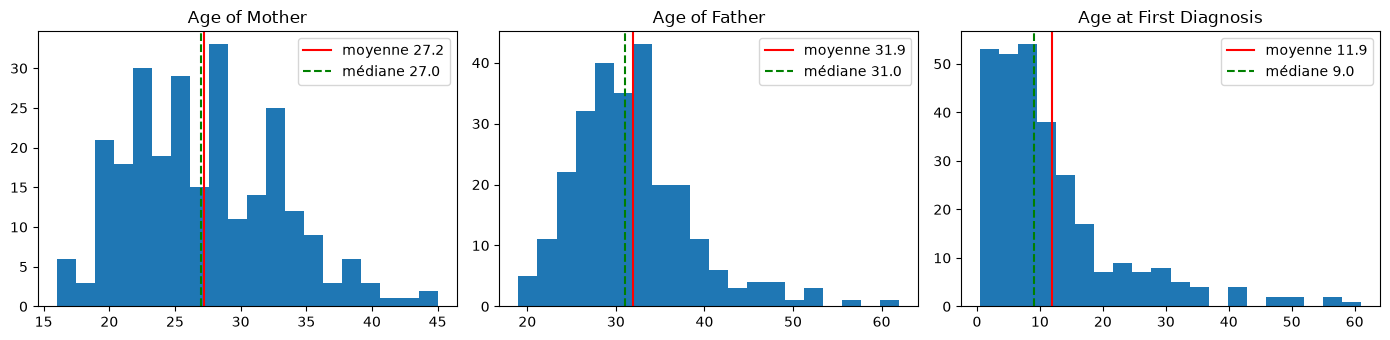

                        moyenne  médiane  asymétrie
Age of Mother             27.18     27.0       0.44
Age of Father             31.88     31.0       1.11
Age at First Diagnosis    11.88      9.0       1.90


In [95]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, c in zip(axes, cols_age):
    serie = df[c].dropna()
    ax.hist(serie, bins=20)
    ax.axvline(serie.mean(), color="red", label=f"moyenne {serie.mean():.1f}")
    ax.axvline(serie.median(), color="green", linestyle="--", label=f"médiane {serie.median():.1f}")
    ax.set_title(c); ax.legend()
plt.tight_layout(); plt.show()

print(pd.DataFrame({"moyenne": df[cols_age].mean(), "médiane": df[cols_age].median(),
                    "asymétrie": df[cols_age].skew()}).round(2))

In [100]:

print("--- 1. DISTRIBUTION DE LA CIBLE (Case Type) ---")
target_dist = df["Case Type"].value_counts().sort_index()
display(target_dist.rename("effectif").to_frame())

print("\n--- 2. TAUX DE VALEURS MANQUANTES POUR LES ÂGES ---")
cols_age = ["Age of Mother", "Age of Father", "Age at First Diagnosis"]
missing_stats = pd.DataFrame({
    "Nb_manquants": df[cols_age].isna().sum(),
    "Taux_(%)": (df[cols_age].isna().mean() * 100).round(2)
})
display(missing_stats)

--- 1. DISTRIBUTION DE LA CIBLE (Case Type) ---


,effectif
Case Type,
0,161
1,135



--- 2. TAUX DE VALEURS MANQUANTES POUR LES ÂGES ---


,Nb_manquants,Taux_(%)
Age of Mother,35,11.82
Age of Father,34,11.49
Age at First Diagnosis,4,1.35


In [101]:
# %% [markdown]
# ## Test de Fisher : Lien entre l'absence des valeurs d'âge et la variable cible

# %%
import pandas as pd
from scipy.stats import fisher_exact

# Copie de travail pour l'analyse des valeurs manquantes
df_missing = df[["Case Type", "Age of Mother", "Age of Father", "Age at First Diagnosis"]].copy()

# Création d'indicateurs binaire d'absence (1 = manquant, 0 = présent)
df_missing["Mother_Missing"] = df_missing["Age of Mother"].isna().astype(int)
df_missing["Father_Missing"] = df_missing["Age of Father"].isna().astype(int)
df_missing["Diag_Missing"] = df_missing["Age at First Diagnosis"].isna().astype(int)

# Fonction pour calculer le test de Fisher sur une variable d'âge
def run_fisher_test(col_name):
    contingency_table = pd.crosstab(df_missing[col_name], df_missing["Case Type"])
    # fisher_exact attend une table de contingence 2x2
    res = fisher_exact(contingency_table)
    return contingency_table, res.pvalue

# Exécution pour les trois variables d'âge
for col in ["Mother_Missing", "Father_Missing", "Diag_Missing"]:
    table, p_val = run_fisher_test(col)
    print(f"\n--- Test de Fisher pour : {col} ---")
    display(table)
    print(f"p-value = {p_val:.4f}")
    if p_val > 0.05:
        print("-> Pas de lien significatif entre l'absence et la cible (p > 0.05).")
    else:
        print("-> Lien statistiquement significatif détecté (p <= 0.05).")


--- Test de Fisher pour : Mother_Missing ---


Case Type,0,1
Mother_Missing,,
0,140,121
1,21,14


p-value = 0.5884
-> Pas de lien significatif entre l'absence et la cible (p > 0.05).

--- Test de Fisher pour : Father_Missing ---


Case Type,0,1
Father_Missing,,
0,141,121
1,20,14


p-value = 0.7149
-> Pas de lien significatif entre l'absence et la cible (p > 0.05).

--- Test de Fisher pour : Diag_Missing ---


Case Type,0,1
Diag_Missing,,
0,159,133
1,2,2


p-value = 1.0000
-> Pas de lien significatif entre l'absence et la cible (p > 0.05).


Séparation Train / Test et Configuration du Pipeline

In [96]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Case Type est déjà codée 0/1; on garde ces valeurs sans supposer leur signification.
y = df["Case Type"].astype("int64")
X = df.drop(columns=["Case Type", "Unnamed: 0"], errors="ignore")

col_mere = ["Age of Mother"]
col_pere = ["Age of Father"]
col_diagnostic = ["Age at First Diagnosis"]
cols_age = col_mere + col_pere + col_diagnostic
cols_bin = [col for col in X.columns if col not in cols_age]

# Séparation rigoureuse avant imputation (anti-fuite de données)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

# Définition du pipeline de prétraitement
prepro = ColumnTransformer(
    transformers=[
        (
            "mere",
            Pipeline(
                steps=[
                    ("imp", SimpleImputer(strategy="mean")),
                    ("sc", StandardScaler()),
                ]
            ),
            col_mere,
        ),
        (
            "pere",
            Pipeline(
                steps=[
                    ("imp", SimpleImputer(strategy="mean")),
                    ("sc", StandardScaler()),
                ]
            ),
            col_pere,
        ),
        (
            "diagnostic",
            Pipeline(
                steps=[
                    ("imp", SimpleImputer(strategy="median")),
                    ("sc", StandardScaler()),
                ]
            ),
            col_diagnostic,
        ),
        ("bin", SimpleImputer(strategy="most_frequent"), cols_bin),
    ]
)

print("Répartition de la cible (codes 0/1) :")
display(y.value_counts().sort_index().rename("effectif").to_frame())
print(f"Dimensions train : {X_train.shape}; dimensions test : {X_test.shape}")

Répartition de la cible (codes 0/1) :


,effectif
Case Type,
0,161
1,135


Dimensions train : (236, 18); dimensions test : (60, 18)


Application et Validation du Pipeline

In [98]:
print("Types des variables explicatives :")
display(X.dtypes.rename("type").to_frame())

print("Valeurs manquantes dans X_train avant le prétraitement :")
display(X_train.isna().sum().loc[lambda x: x > 0].rename("valeurs_manquantes").to_frame())

# Ajustement sur le train et transformation des deux jeux
X_train_prepared = prepro.fit_transform(X_train)
X_test_prepared = prepro.transform(X_test)
print(f"\nDonnées prétraitées : train {X_train_prepared.shape}, test {X_test_prepared.shape}")

Types des variables explicatives :


,type
Tumour Case,int64
Age of Mother,float64
Age of Father,float64
Age at First Diagnosis,float64
Café au lait (CLS),int64
Axillary Freckles,int64
Inguinal Freckles,int64
Lisch Nodules,int64
Dermal Neurofibromins,int64
Plexiform Neurofibromins,int64


Valeurs manquantes dans X_train avant le prétraitement :


,valeurs_manquantes
Age of Mother,26
Age of Father,23
Age at First Diagnosis,3



Données prétraitées : train (236, 18), test (60, 18)



### 1. Pourquoi imputer plutôt que supprimer la colonne ?

Supprimer une colonne représente une perte d'information définitive. L'imputation est peu risquée ici car les valeurs manquantes sont rares (11,8 % pour la mère, 11,5 % pour le père et 1,4 % pour le diagnostic).

---

### 2. Pourquoi ne pas supprimer les lignes incomplètes ?
Supprimer toutes les lignes incomplètes ferait perdre entre 35 et 73 patients (soit 12 à 25 % du jeu de données), ce qui est considérable sur un échantillon déjà restreint.
Comme les tests statistiques (Fisher) démontrent que l'absence de données n'est pas liée à la variable cible, la suppression ne biaiserait pas l'échantillon, mais elle l'appauvrirait inutilement en réduisant la puissance statistique.

---

### 3. Faut-il ajouter un indicateur de valeur manquante (`add_indicator=True`) ?

Les tests de Fisher montrant que l'absence n'est pas liée à la cible, l'indicateur a peu de chances d'apporter une aide significative et risque d'ajouter des colonnes bruitées.

---

### 4. Faut-il utiliser la moyenne ou la médiane ?

* est privilégiée pour les trois âges, car elle est robuste aux valeurs extrêmes et aux asymétries (par exemple, l'âge au diagnostic est souvent très asymétrique avec beaucoup d'enfants et quelques adultes). par contre y'a pas une gande difference entre la médianne et la moyenne pour l'age des parents
---

### 5. Quel est l'intérêt de l'âge du père et comment trancher son utilité ?

 L'étude de Sharafi et al. (2018) conclut qu'il n'y a pas d'effet démontré de l'âge des parents sur la *gravité* clinique de la NF1. Cependant, notre projet cible la distinction entre cas sporadique et familial (l'hypothèse étant qu'une mutation nouvelle est plus fréquente chez un père plus âgé). On teste l'effet de l'âge du père via un boxplot et un test de Mann-Whitney, mais la décision finale de garder ou non la variable se prend objectivement grâce à une comparaison de modèles en validation croisée imbriquée (avec vs sans l'âge du père).

---

### 6. Comment expliquer l'écart de cohorte entre la page UCI (309 cas) et nos données (296 patients) ?

Bien que la notice descriptive initiale du dépôt UCI mentionne de manière erronée une cohorte théorique de 309 cas, l'analyse du fichier source brut mis à disposition recense effectivement **296 patients exploitables** (161 de classe 0 et 135 de classe 1), sans valeur manquante sur la variable cible.inspecter le fichier brut d'origine avec un tableau croisé pour vérifier si le filtre a par inadvertance retiré de vrais patients portant un type de cas.